# Case Study 19 — A/B Tests That Can Be Trusted: Variance Reduction, Peeking, Marketplace Interference and Switchback Experiments

**Priority:** ★★★ Must-visit · **Reference:** Case Study 19 — *Cabify switchback experiments; Flipkart's early A/B framework* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Product, Growth, Marketplace/Supply team, Finance, Experimentation platform owners
**Data:** ⚠️ **SYNTHETIC** (D-19-01). No company experiment logs are public; this is a calibrated simulation with a **hidden true effect**, so we can check whether each method recovers the truth.
**Evidence level:** Medium. Documented: Cabify's switchback logic. Not documented: any test statistic, variance estimator or lift. This notebook is an interview-standard solution on simulated data.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs19_experimentation_ab_testing.ipynb`

## 0. Executive Summary for Business

*(Synthetic experiments with a hidden true effect, built on the documented design of Cabify's switchback tests and Flipkart's early A/B framework. Neither company's data or results are reproduced; the public sources give no test statistics. Written after the analysis.)*

- **The question:** how do we know an experiment can be trusted, how long must it run, and when does a user-level A/B test give the wrong answer for a marketplace?
- **The homepage test was invalid until we fixed it.** Overall there was a sample-ratio mismatch (treatment share 49.1%, p = 1.7e-9), caused by web users on days 5 and 6 (treatment share 31% and 34%). After removing those 4,893 users from both arms the share is 49.8% (p = 0.26) and covariates are balanced (p = 0.69).
- **The new homepage lifts conversion, not clearly revenue.** Conversion rises from 7.31% to 7.94% (**+8.6% relative**, 95% CI +0.32 to +0.94 points, Holm p = 0.0004). Winsorised revenue per user is **+₹4.4 (CI -₹0.8 to +₹9.5)**, not significant. The raw revenue difference of ₹78 looks significant but comes from 25 users above ₹1 lakh (18 treatment, 7 control).
- **Guardrails pass, but narrowly on support.** Bounce rate, page load (+1.0%, +22 ms) and support contacts (+0.14 points) are all non-inferior to their margins, with support contacts close to its margin (p = 0.047).
- **Variance reduction helps only a little here.** Pre-period covariates cut variance by **7.6% for conversion and 4.9% for revenue** (ANCOVA); the boosted-tree version (CUPAC) adds almost nothing (8.1% and 4.9%). The A/A tests keep false positives near 5%.
- **Peeking is costly.** Testing at 1.96 after each of 5 batches gives a **14.3% false-positive rate**. O'Brien-Fleming holds it at 5.1% with 79% power.
- **In the marketplace, the user-level A/B overstates.** It shows **+7.2%** completed trips against a true global-rollout lift of **+4.1%**, and shows no success-rate harm (+0.05 points) where the truth is **-1.49 points**. A switchback with a 10-minute washout gives +3.1% (CI 1.4% to 4.8%).
- **Design matters a lot.** Over 120 replications, alternating 60-minute slots are biased by -3.3 points (coverage 0%); paired-random 53-minute slots with a 10-minute washout have bias -0.6 points and 92% coverage. All switchbacks here understate the lift.
- **Money:** the naive A/B implies about **₹78 crore a year** for the marketplace message; the truth is ₹44 crore and the switchback gives ₹33 crore. The homepage base case is **₹16 crore a year contribution** (range -₹0.3 to +₹41 crore).
- **I recommend:** ramp the homepage on the conversion win while holding back 5% to measure revenue; use paired-random 53-minute switchbacks with a washout for marketplace changes; use O'Brien-Fleming looks if the team must peek.

## 1. The Problem in Simple English

Every product change at an ecommerce or delivery company is judged by an experiment: show the change to some customers, keep others on the old version, compare. That sounds simple, but four things routinely go wrong:

1. **The groups are not really random** (a logging bug loses some users from one group), so the comparison is unfair.
2. **The effect is small and the data is noisy**, so a real improvement looks like luck, or luck looks like an improvement. Looking at the results every day and stopping when they look good makes this much worse.
3. **Customers share something limited.** In a delivery or ride-hailing marketplace, treated and control customers draw on the **same pool of delivery partners**. If the new version makes treated customers order more, control customers find fewer partners. The test then **overstates** what a full launch would do. Cabify calls this "cannibalization".
4. **The fix is to randomise time instead of people** (a *switchback* test): everybody sees version A in some time slots and version B in others. That removes the sharing problem but brings new ones: carryover from one slot to the next, slot length, and few independent observations.

Leaders and interviewers want to know:
1. How do we check that an experiment was run properly?
2. How much traffic and time does it need, and how do we shorten it (CUPED)?
3. What is the risk of peeking, and what is the alternative?
4. When does a user-level A/B test give the wrong answer, and by how much?
5. How do we design and analyse a switchback test (interval length, washout, assignment)?

## 2. Reference from the Case File

### (a) What Cabify and Flipkart did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem (Cabify) | User-level A/B groups share the driver pool. Treated users create more journeys, which lowers the success rate for control users ("cannibalization"), so A/B results mislead for marketplace-wide metrics |
| Approach (Cabify) | **Switchback**: every user sees the same version at a given time; the group is the time slot. The interval is chosen to cover all hour/day combinations; the example is **53 minutes (a prime number, to avoid cycling effects)**, with 58, 112 and 29 minutes as alternatives |
| Carryover (Cabify) | Switch less often when effects persist; **washout periods** that drop early-treatment data. Duration depends on MDE and sample size, cost, uncertainty in the sample rate, and blocking with other experiments (e.g. by region). The sample unit is the interval |
| Statistics (Cabify) | "The same statistics as A/B tests". The specific test statistic, variance estimator or CUPED-type adjustment is **not documented** (ND). DoorDash material on cluster-robust errors appeared only in a search snippet and is not treated as documented |
| Flipkart (2012) | Amod Malviya's framework with a real-time metrics dashboard; **10% of traffic** routed to the new design, rolled back if sales dip. No statistics described (ND). Context figures (press): sales of ₹75 crore a month, revenue doubling every quarter for eight quarters, not attributed causally |
| Impact | No numeric lift for Cabify's example (ND) |

**Sources:** Cabify Engineering, "Why do you need switchback experimentation", Albert Rego, 4 Mar 2026; CIO India, "Flipkart Drives Innovation Through Intelligent use of IT", 21 May 2012.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| World 1: homepage A/B | 120,000 users, 50/50, 14 days, **8 metrics** (conversion, orders, revenue, add-to-cart, wishlist, and three guardrails), pre-period covariates, and defects: duplicates, missing values, revenue outliers, and a **logging outage that causes a sample-ratio mismatch** |
| World 2: marketplace | 28 days at minute level. A message change raises requests by **6%** for treated users. Success falls when total demand rises against limited supply. Effect builds up over a **12-minute** carryover. The hidden truth is the effect of a **global rollout** |
| Methods added | **SRM** test; Welch tests with **Holm / BH**; **non-inferiority** tests for guardrails; **CUPED** and regression adjustment, validated by repeated A/A tests; **power / MDE**; **peeking simulation** with group-sequential boundaries; cluster-robust switchback estimator; **replication study** of eight switchback designs and a user-level A/B for bias, RMSE and coverage; **CUPAC** (gradient-boosting covariate) |
| Numbers | Every lift, interval length effect and variance reduction here is **simulated**; none is a Cabify or Flipkart figure |

### (c) How the industry uses this

Every large Indian consumer company runs an experimentation platform (Flipkart's 2012 framework; Swiggy's in-house platform is reported but its posts could not be read). SRM checks, guardrail metrics, CUPED and sequential monitoring are standard platform features; switchbacks are used for supply-sharing marketplaces (delivery, dispatch, pricing). This is among the most-asked data-science interview topics: "how would you test this?", "why is the p-value not enough?", "what if control and treatment interact?".

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can we trust what our experiments say, and can we evaluate changes to a shared-supply marketplace? |
| Analytical | Is the homepage test valid and what does it show; how much do variance reduction and sequential rules help; how large is the interference bias of a user-level A/B; which switchback design recovers the true global effect? |

**Hypotheses**
- **H1 (validity):** H0: the arm split is 50/50 and pre-period covariates are balanced (chi-square SRM test; standardised mean differences; joint logistic test).
- **H2 (effect):** H0: the redesign has zero effect on each metric (Welch tests; Holm and BH across the eight; non-inferiority margins for guardrails).
- **H3 (variance reduction):** H0: CUPED leaves the standard error unchanged and keeps false positives at 5% (repeated A/A on control users).
- **H4 (peeking):** H0: checking five times with p < 0.05 keeps the false-positive rate at 5%.
- **H5 (interference):** H0: a user-level A/B estimates the global-rollout effect without bias in a shared-supply marketplace.
- **H6 (switchback):** H0: the switchback estimator is unbiased with 95% coverage; interval length, assignment rule and washout do not matter.

**Primary metric:** conversion (users with ≥ 1 order in 14 days). **Marketplace metric:** completed trips per minute (and success rate). **Guardrails:** bounce rate, page-load time, support contacts.

In [1]:
import sys, warnings, importlib, os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian ecommerce / delivery experiment logs | **None.** Companies do not publish experiment data. Public A/B sets (e.g. Criteo uplift, marketing A/B on Kaggle) are advertising data with no shared-supply interference and no known truth. |
| **Decision** | Two simulated worlds with a hidden true effect, so that bias and coverage can be measured, not just estimated (D-19-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs19.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 19 (A/B testing, interference and switchback experiments)
================================================================================================
THIS DATA IS SYNTHETIC. No company experiment logs are public.

Documented context (reference file, Case 19): Cabify (4 Mar 2026) explains that user-level A/B tests are biased for
marketplace-wide metrics because treated and control users draw on the same driver pool ("cannibalization"); its
switchback design makes the time slot the unit, uses a prime interval (53 minutes; alternatives 58, 112, 29), and
handles carryover with washout periods. Flipkart (CIO India, 2012) routed 10% of traffic to a new design and rolled
back if sales dipped. No lift figures, test statistics or variance estimators are public (ND).

Two simulated worlds:
  1. A user-level A/B test of a homepage redesign on an ecommerce site (120,000 users, 50/50, 14 days, 8 metrics,
     pre-period covariates for CUPED, built-in defects: duplicates, missing values, revenue outliers, and a logging
     outage that causes a sample-ratio mismatch).
  2. A ride-hailing style marketplace at minute level (28 days) with a shared supply pool. A message change raises
     requests by TAU = 6% for treated users. Success probability falls when total demand rises against fixed supply, so
     treated users cannibalise control users. The hidden truth is the effect of a GLOBAL rollout (everyone treated).
     Carryover: the behavioural effect builds up with a 12-minute exponential time constant after a switch.
     Supply has a 120-minute cycle (shift/batching pattern), which a 60-minute alternating design would alias with.
Hidden ground-truth columns / values are prefixed with "_".

Outputs: data/cs19/users_ab.csv.gz, market_switchback.csv.gz, market_userab.csv.gz, truth.json
"""
import json
import os
import numpy as np
import pandas as pd
from scipy.signal import lfilter

SEED = 42
N_USERS = 120_000; EXP_DAYS = 14
DAYS_M = 28; TAU = 0.06; CARRY_TC = 12.0; K_SUCC = 1.8; P_MAX = 0.97


def _sigmoid(x):
    return 1 / (1 + np.exp(-x))


# ------------------------------------------------------------------ world 1: user-level A/B
def generate_users(rng, n=N_USERS):
    new = rng.random(n) < 0.30; plat = np.where(rng.random(n) < 0.62, "app", "web"); tier = rng.choice(["metro", "tier2", "tier3"], n, p=[0.40, 0.35, 0.25])
    z = rng.normal(0, 1, n)                                              # latent engagement
    pre_orders = np.where(new, 0, rng.poisson(1.1 * np.exp(1.3 * z - 0.6)))
    pre_sessions = np.where(new, rng.poisson(1.0, n), rng.poisson(4.0 * np.exp(0.5 * z)))
    pre_spend = np.where(pre_orders > 0, np.round(pre_orders * np.exp(rng.normal(6.4 + 0.2 * z, 0.5)), 0), 0.0)
    day = rng.integers(0, EXP_DAYS, n); arm = (rng.random(n) < 0.5).astype(int)
    # true relative lifts (hidden): conversion +15% for new users, +3% for existing; orders follow; wishlist no effect
    lift = np.where(new, 0.15, 0.03)
    logit0 = -3.4 + 1.4 * z + 0.25 * (plat == "app") - 0.15 * (tier == "tier3")
    p0 = _sigmoid(logit0); p1 = np.clip(p0 * (1 + lift), 0, 0.95); conv = (rng.random(n) < np.where(arm == 1, p1, p0)).astype(int)
    extra = rng.poisson(0.35 * np.exp(0.3 * z)) * conv; orders = conv + extra
    aov = np.exp(rng.normal(6.35, 0.75, n))
    revenue = np.where(orders > 0, orders * aov * np.exp(rng.normal(0, 0.25, n)), 0.0)
    cart = ((rng.random(n) < _sigmoid(-1.5 + 0.6 * z + 0.9 * conv + 0.05 * arm)) | (conv == 1)).astype(int)
    wish = rng.poisson(0.5 * np.exp(0.3 * z), n)
    bounce = (rng.random(n) < _sigmoid(-0.9 - 0.4 * z + 0.0 * arm)).astype(int)
    load = np.round(np.exp(rng.normal(np.log(1900), 0.35, n)) * np.where(plat == "web", 1.25, 1.0) * np.where(arm == 1, 1.012, 1.0), 0)
    support = (rng.random(n) < _sigmoid(-3.6 - 0.2 * z + 0.05 * (arm == 1) + 0.3 * conv)).astype(int)
    df = pd.DataFrame({"user_id": np.arange(n), "arm": arm, "day": day, "platform": plat, "city_tier": tier, "new_user": new.astype(int), "pre_orders_28d": pre_orders,
                       "pre_sessions_28d": pre_sessions, "pre_spend_28d": pre_spend, "converted": conv, "orders": orders, "revenue_inr": np.round(revenue, 0),
                       "add_to_cart": cart, "wishlist_adds": wish, "bounced": bounce, "page_load_ms": load, "support_contact": support,
                       "_true_rel_lift_conv": lift, "_latent_engagement": np.round(z, 3)})
    # defects
    out = rng.choice(n, 25, replace=False); df.loc[out, "revenue_inr"] = np.round(rng.uniform(150_000, 600_000, 25), 0); df.loc[out, "converted"] = 1; df.loc[out, "orders"] = np.maximum(df.loc[out, "orders"], 1)
    df.loc[rng.choice(n, int(0.03 * n), replace=False), "pre_spend_28d"] = np.nan
    df.loc[rng.choice(n, int(0.01 * n), replace=False), "page_load_ms"] = np.nan
    outage = (df.platform == "web") & df.day.isin([5, 6]) & (df.arm == 1) & (rng.random(n) < 0.5)           # logging outage: treated web rows lost on days 5-6
    df = df[~outage]
    df = pd.concat([df, df.sample(n=1500, random_state=SEED)], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
    return df


# ------------------------------------------------------------------ world 2: marketplace with shared supply
def market_paths(rng, days=DAYS_M):
    T = days * 1440; t = np.arange(T); h = (t % 1440) / 60.0; dow = (t // 1440) % 7
    shape = 0.55 + 0.45 * np.exp(-((h - 8.5) / 1.8) ** 2) + 0.60 * np.exp(-((h - 18.5) / 2.2) ** 2)
    weekly = np.where(dow >= 5, 0.90, 1.0)
    ar = lambda phi, sd: lfilter([sd * np.sqrt(1 - phi ** 2)], [1, -phi], rng.normal(0, 1, T))
    lam = 100 * shape * weekly * np.exp(ar(0.99, 0.05))
    sup = 76 * (0.8 + 0.35 * shape) * (1 + 0.10 * np.sin(2 * np.pi * t / 120)) * np.exp(ar(0.995, 0.07))
    return dict(t=t, hour=h, day=t // 1440, lam=lam, sup=sup)


def p_succ(sup, demand):
    return P_MAX * (1 - np.exp(-K_SUCC * sup / np.maximum(demand, 1e-9)))


def ewma(a, tc=CARRY_TC):
    al = np.exp(-1 / tc); return lfilter([1 - al], [1, -al], a, zi=[a[0] * al])[0] if tc > 0 else a


def truth_global(paths):
    """Hidden truth for a GLOBAL rollout: relative lift in completed trips and change in success rate (pp)."""
    d0 = paths["lam"]; d1 = d0 * (1 + TAU); c0 = (d0 * p_succ(paths["sup"], d0)).sum(); c1 = (d1 * p_succ(paths["sup"], d1)).sum()
    return dict(_rel_lift_completed=c1 / c0 - 1, _success_pp=100 * (c1 / d1.sum() - c0 / d0.sum()), _naive_ab_rel_lift=TAU)


def simulate_market(rng, paths, a_raw, tau=TAU):
    """a_raw: per-minute treatment indicator or fraction (0..1). Returns minute-level DataFrame."""
    a = ewma(np.asarray(a_raw, float)); mu = paths["lam"] * (1 + tau * a); req = rng.poisson(mu); p = p_succ(paths["sup"], np.maximum(req, 1)); comp = rng.binomial(req, np.clip(p, 0, 1))
    return pd.DataFrame({"minute": paths["t"], "day": paths["day"], "hour": paths["hour"], "treat": np.asarray(a_raw, float), "requests": req, "completed": comp, "supply": paths["sup"]})


def interval_assignment(rng, T, length, mode):
    """Per-minute 0/1 assignment. mode: 'alternate', 'random', 'block' (paired random order of consecutive intervals)."""
    k = int(np.ceil(T / length)); n = k + (k % 2)
    if mode == "alternate": a = np.arange(n) % 2
    elif mode == "random": a = rng.integers(0, 2, n)
    elif mode == "block": a = np.concatenate([rng.permutation([0, 1]) for _ in range(n // 2)])
    else: raise ValueError(mode)
    return np.repeat(a, length)[:T].astype(float), np.repeat(np.arange(n), length)[:T]


def user_level_market_ab(rng, paths, n_users=50_000):
    arm = (rng.random(n_users) < 0.5).astype(int); rate = rng.gamma(0.9, 3.0 / 0.9, n_users); req = rng.poisson(rate * (1 + TAU * arm))
    m = simulate_market(rng, paths, np.full(len(paths["t"]), 0.5)); p_bar = m.completed.sum() / m.requests.sum(); comp = rng.binomial(req, p_bar)
    return pd.DataFrame({"user_id": np.arange(n_users), "arm": arm, "requests": req, "completed": comp}), p_bar


def generate(seed=SEED):
    ss = np.random.SeedSequence(seed).spawn(4); r1, r2, r3, r4 = [np.random.default_rng(s) for s in ss]
    users = generate_users(r1)
    paths = market_paths(r2); T = len(paths["t"]); a_raw, interval = interval_assignment(r3, T, 53, "block")
    sb = simulate_market(r3, paths, a_raw); sb["interval"] = interval
    sb.loc[sb.sample(frac=0.002, random_state=seed).index, ["requests", "completed"]] = np.nan                      # missing minutes
    sb.loc[sb.sample(n=15, random_state=seed + 1).index, "supply"] *= 4                                         # sensor spikes
    sb = pd.concat([sb, sb.sample(n=300, random_state=seed)], ignore_index=True).sort_values("minute", kind="stable").reset_index(drop=True)
    uab, p_bar = user_level_market_ab(r4, paths)
    tr = truth_global(paths); tr["_ab_success_rate"] = p_bar
    return users, sb, uab, tr, paths


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); out = os.path.join(here, "cs19"); os.makedirs(out, exist_ok=True)
    users, sb, uab, tr, _ = generate()
    users.to_csv(os.path.join(out, "users_ab.csv.gz"), index=False); sb.to_csv(os.path.join(out, "market_switchback.csv.gz"), index=False); uab.to_csv(os.path.join(out, "market_userab.csv.gz"), index=False)
    json.dump({k: float(v) for k, v in tr.items()}, open(os.path.join(out, "truth.json"), "w"))
    u = users.drop_duplicates("user_id")
    print(len(users), "user rows |", len(u), "unique | treated share", round(u.arm.mean(), 4), "| conv", round(u.converted.mean(), 4), "| corr(pre_spend, revenue)", round(u[["pre_spend_28d", "revenue_inr"]].corr().iloc[0, 1], 3))
    print("conv by arm", u.groupby("arm").converted.mean().round(4).to_dict(), "| rev by arm", u.groupby("arm").revenue_inr.mean().round(1).to_dict())
    print("truth", {k: round(v, 4) for k, v in tr.items()})
    ab = uab.groupby("arm").agg(req=("requests", "mean"), comp=("completed", "mean")); print(ab, "naive ratio", ab.comp[1] / ab.comp[0])
    m = sb.dropna(subset=["requests"]); print("market: success rate", round(m.completed.sum() / m.requests.sum(), 3), "| mean requests/min", round(m.requests.mean(), 1))

Overwriting data/generate_cs19.py


In [3]:
os.makedirs("data/cs19", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs19 as gen; importlib.reload(gen)
t0 = time.time(); users_raw, sb_raw, uab, TR, PATHS = gen.generate(seed=SEED)
users_raw.to_csv("data/cs19/users_ab.csv.gz", index=False); sb_raw.to_csv("data/cs19/market_switchback.csv.gz", index=False); uab.to_csv("data/cs19/market_userab.csv.gz", index=False)
json.dump({k: float(v) for k, v in TR.items()}, open("data/cs19/truth.json", "w"))
print(f"{len(users_raw):,} user rows | {len(sb_raw):,} minute rows | {len(uab):,} marketplace users | generated in {time.time() - t0:.0f}s")
users_raw.head(4)

119,955 user rows | 40,620 minute rows | 50,000 marketplace users | generated in 41s


,user_id,arm,day,platform,city_tier,new_user,pre_orders_28d,pre_sessions_28d,pre_spend_28d,converted,orders,revenue_inr,add_to_cart,wishlist_adds,bounced,page_load_ms,support_contact,_true_rel_lift_conv,_latent_engagement
0,107932,0,8,app,metro,0,0,2,0.0000,0,0,0.0000,0,2,0,"1,380.0000",0,0.0300,-0.9770
1,56043,0,4,web,tier2,0,2,6,893.0000,0,0,0.0000,1,2,0,"2,213.0000",0,0.0300,0.7120
2,5020,1,11,web,tier3,1,0,1,0.0000,0,0,0.0000,0,0,0,"1,827.0000",0,0.1500,0.1240
3,69023,1,12,web,tier2,0,0,5,0.0000,0,0,0.0000,1,0,0,"2,843.0000",0,0.0300,-0.3060


| Parameter | Value | Basis |
|---|---|---|
| Homepage test | 120,000 users, 50/50, 14 days; baseline conversion ≈ 7.4%; revenue per user ≈ ₹88 | Our assumption |
| True effect (hidden) | +15% relative conversion for new users (30% of users), +3% for existing; wishlist and bounce unaffected; page load +1.2% | Our assumption |
| Marketplace | 28 days × 1,440 minutes; peaks at 08:30 and 18:30; weekend demand −10%; supply has a 120-minute cycle | Our assumption |
| Interference | Success probability = 0.97 × (1 − exp(−1.8 × supply / demand)); treatment raises requests by 6% | Our assumption (the mechanism is **documented** qualitatively by Cabify) |
| Carryover | Behavioural effect builds up with a 12-minute time constant after a switch | Our assumption (Cabify documents carryover, not its size) |
| Switchback | 53-minute intervals, paired-random assignment | **Documented** interval length |
| DQ issues | 1,500 duplicate rows; 3% missing pre-spend; 25 revenue outliers (₹1.5–6 lakh); logging outage that drops half of treated web users on days 5–6; missing minutes, duplicated minutes and supply sensor spikes in the market data | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("users_ab: user_id, arm, day, platform, city_tier, new_user", "User, arm (1 = new homepage), day of entry 0–13, platform, city tier, new-customer flag"),
    ("users_ab: pre_orders_28d, pre_sessions_28d, pre_spend_28d", "Pre-experiment covariates (used by CUPED)"),
    ("users_ab: converted, orders, revenue_inr", "Outcomes over 14 days"),
    ("users_ab: add_to_cart, wishlist_adds, bounced, page_load_ms, support_contact", "Secondary metrics and guardrails"),
    ("market_switchback: minute, day, hour, interval, treat, requests, completed, supply", "Minute-level marketplace; interval = 53-minute switchback slot; supply = available driver capacity"),
    ("market_userab: user_id, arm, requests, completed", "The same marketplace tested by a user-level 50/50 A/B"),
    ("_true_rel_lift_conv, _latent_engagement, truth.json", "HIDDEN: true effect and engagement; global-rollout truth (never used for fitting)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs19/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"users_ab: user_id, arm, day, platform, city_ti...","User, arm (1 = new homepage), day of entry 0–1..."
1,"users_ab: pre_orders_28d, pre_sessions_28d, pr...",Pre-experiment covariates (used by CUPED)
2,"users_ab: converted, orders, revenue_inr",Outcomes over 14 days
3,"users_ab: add_to_cart, wishlist_adds, bounced,...",Secondary metrics and guardrails
4,"market_switchback: minute, day, hour, interval...",Minute-level marketplace; interval = 53-minute...
5,"market_userab: user_id, arm, requests, completed",The same marketplace tested by a user-level 50...
6,"_true_rel_lift_conv, _latent_engagement, truth...",HIDDEN: true effect and engagement; global-rol...


## 5. Data Quality Checks

In [5]:
U0 = users_raw
m0_ = sb_raw
roll = m0_.drop_duplicates("minute").supply.rolling(101, center=True, min_periods=1).median().values
sp_chk = m0_.drop_duplicates("minute").supply.values > 1.8 * roll
checks = {
    "user rows": len(U0), "duplicate user rows": int(U0.duplicated("user_id").sum()), "missing pre_spend_28d": int(U0.pre_spend_28d.isna().sum()), "missing page_load_ms": int(U0.page_load_ms.isna().sum()),
    "revenue outliers (> ₹1 lakh)": int((U0.revenue_inr > 1e5).sum()), "share of all revenue from those outliers": float(U0.loc[U0.revenue_inr > 1e5, "revenue_inr"].sum() / U0.revenue_inr.sum()),
    "market: duplicate minute rows": int(m0_.duplicated("minute").sum()), "market: minutes with missing requests": int(m0_.drop_duplicates("minute").requests.isna().sum()), "market: supply spikes (> 1.8× rolling median)": int(sp_chk.sum()),
}
print(pd.Series(checks, name="value").to_string())
U = U0.drop_duplicates("user_id").copy()
for c in ("pre_spend_28d",):
    U[c + "_missing"] = U[c].isna().astype(int); U[c] = U[c].fillna(U.groupby("new_user")[c].transform("median"))
U["page_load_ms"] = U.page_load_ms.fillna(U.page_load_ms.median())
CAP = U.revenue_inr.quantile(0.999); U["rev_w"] = U.revenue_inr.clip(upper=CAP)
sb = m0_.drop_duplicates("minute").sort_values("minute").reset_index(drop=True); rl = sb.supply.rolling(101, center=True, min_periods=1).median(); spk = sb.supply > 1.8 * rl; sb.loc[spk, "supply"] = rl[spk]
print(f"\nClean: {len(U):,} users | revenue winsorised at the 99.9th percentile (₹{CAP:,.0f}) | {len(sb):,} market minutes ({sb.requests.isna().sum()} with missing counts, dropped from estimation)")

user rows                                       119,955.0000
duplicate user rows                               1,500.0000
missing pre_spend_28d                             3,602.0000
missing page_load_ms                              1,199.0000
revenue outliers (> ₹1 lakh)                         25.0000
share of all revenue from those outliers              0.4709
market: duplicate minute rows                       300.0000
market: minutes with missing requests                81.0000
market: supply spikes (> 1.8× rolling median)        15.0000



Clean: 118,455 users | revenue winsorised at the 99.9th percentile (₹6,324) | 40,320 market minutes (81 with missing counts, dropped from estimation)


**Observation:** the 119,955 user rows had **1,500 duplicates, 3,602 missing pre-spend values and 1,199 missing page-load values**. **25 users spent over ₹1 lakh and account for 47% of all revenue**, so revenue is winsorised at ₹6,324. We imputed the missing values (pre-spend by customer-type median) and left 118,455 users. In the marketplace data we removed 300 duplicate minutes, smoothed 15 supply spikes and kept 40,320 minutes, 81 of which have missing counts and are not used in estimation. The outlier problem is serious enough that it changes the revenue conclusion in section 7.2.

## 6. Exploratory Data Analysis

### 6.1 The homepage test data

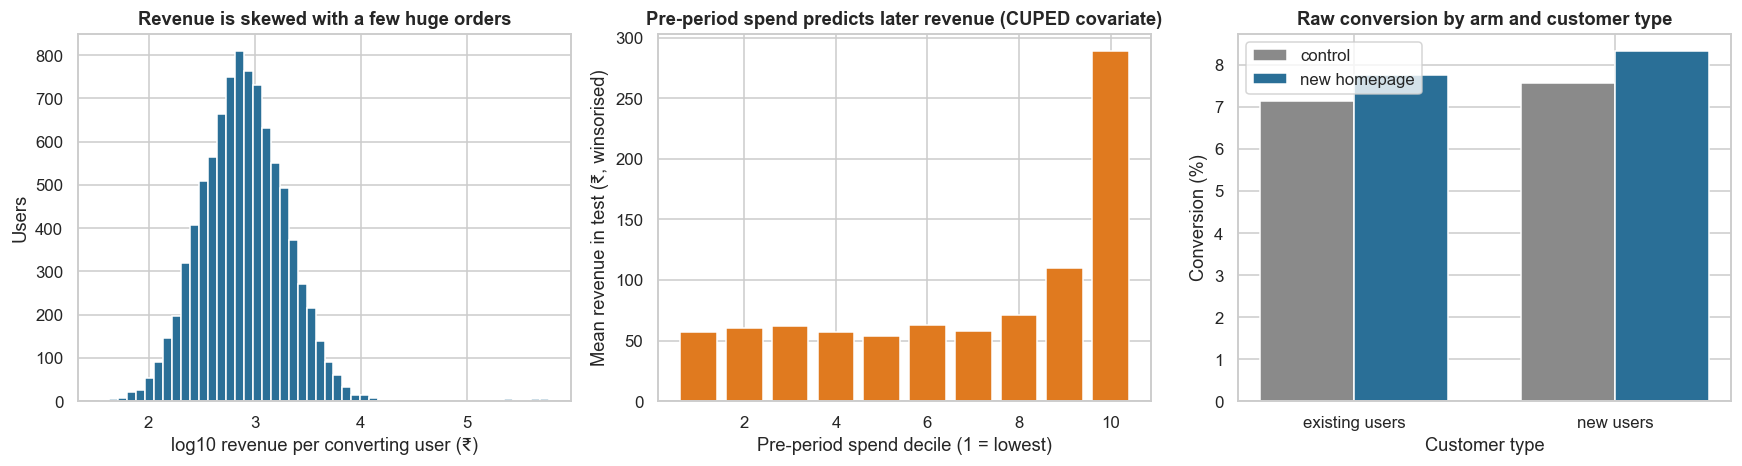

Conversion 7.59% | mean revenue ₹169.7 (winsorised ₹88.1) | corr(pre-spend, revenue, winsorised) = 0.164 | new users 30%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
rv = U.loc[U.revenue_inr > 0, "revenue_inr"]; axes[0].hist(np.log10(rv), bins=50, color="#2a6f97"); axes[0].set_xlabel("log10 revenue per converting user (₹)"); axes[0].set_ylabel("Users"); axes[0].set_title("Revenue is skewed with a few huge orders")
dec = pd.qcut(U.pre_spend_28d.rank(method="first"), 10, labels=False); g = U.groupby(dec).rev_w.mean()
axes[1].bar(g.index + 1, g.values, color="#e07a1f"); axes[1].set_xlabel("Pre-period spend decile (1 = lowest)"); axes[1].set_ylabel("Mean revenue in test (₹, winsorised)"); axes[1].set_title("Pre-period spend predicts later revenue (CUPED covariate)")
cv = U.groupby(["new_user", "arm"]).converted.mean().unstack(); xs = np.arange(2); axes[2].bar(xs - 0.18, cv[0].values * 100, 0.36, label="control", color="#8a8a8a"); axes[2].bar(xs + 0.18, cv[1].values * 100, 0.36, label="new homepage", color="#2a6f97")
axes[2].set_xticks(xs); axes[2].set_xticklabels(["existing users", "new users"]); axes[2].set_xlabel("Customer type"); axes[2].set_ylabel("Conversion (%)"); axes[2].set_title("Raw conversion by arm and customer type"); axes[2].legend()
plt.tight_layout(); plt.show()
print(f"Conversion {U.converted.mean():.2%} | mean revenue ₹{U.revenue_inr.mean():,.1f} (winsorised ₹{U.rev_w.mean():,.1f}) | corr(pre-spend, revenue, winsorised) = {U[['pre_spend_28d', 'rev_w']].corr().iloc[0, 1]:.3f} | new users {U.new_user.mean():.0%}")

**Takeaway:** conversion is **7.59%** overall; mean revenue is ₹169.7 raw but **₹88.1 winsorised**, so the heavy tail doubles the raw mean. Pre-period spend correlates **0.164** with later revenue, so it is a usable (but not strong) covariate for variance reduction. New users are 30% of the sample. The raw bars by arm and customer type are only descriptive; they carry no adjustment or test.

### 6.2 The marketplace: why a shared pool matters

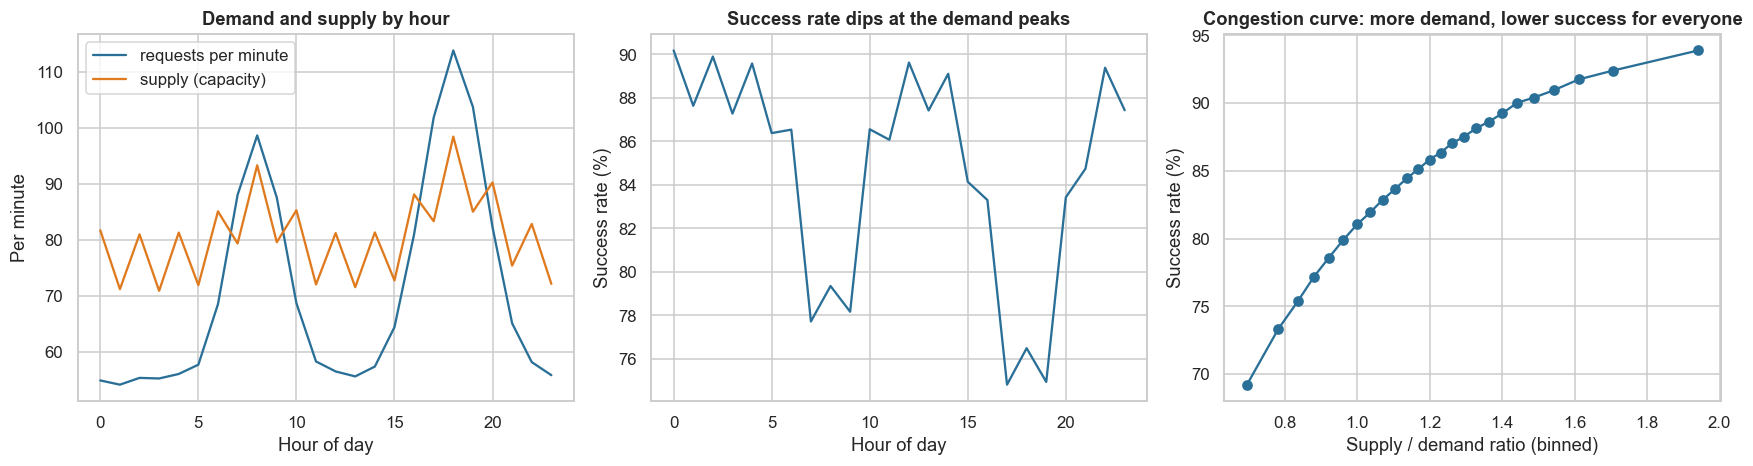

Success rate overall 82.9% | lowest hour 74.8% (hour 17) | highest hour 90.2% | requests/minute 70.8


In [7]:
mk = sb.dropna(subset=["requests"]).copy(); mk["hr"] = mk.hour.astype(int); mk["ratio"] = mk.supply / mk.requests.clip(lower=1); mk["sr"] = mk.completed / mk.requests.clip(lower=1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4)); hh = mk.groupby("hr").agg(req=("requests", "mean"), sup=("supply", "mean"), sr=("sr", "mean"))
axes[0].plot(hh.index, hh.req, color="#2a6f97", label="requests per minute"); axes[0].plot(hh.index, hh.sup, color="#e07a1f", label="supply (capacity)"); axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Per minute"); axes[0].set_title("Demand and supply by hour"); axes[0].legend()
axes[1].plot(hh.index, hh.sr * 100, color="#2a6f97"); axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("Success rate (%)"); axes[1].set_title("Success rate dips at the demand peaks")
bins = pd.qcut(mk.ratio, 25); gb = mk.groupby(bins).agg(r=("ratio", "mean"), s=("sr", "mean")); axes[2].plot(gb.r, gb.s * 100, "o-", color="#2a6f97"); axes[2].set_xlabel("Supply / demand ratio (binned)"); axes[2].set_ylabel("Success rate (%)"); axes[2].set_title("Congestion curve: more demand, lower success for everyone")
plt.tight_layout(); plt.show()
print(f"Success rate overall {mk.completed.sum() / mk.requests.sum():.1%} | lowest hour {hh.sr.min():.1%} (hour {hh.sr.idxmin()}) | highest hour {hh.sr.max():.1%} | requests/minute {mk.requests.mean():.1f}")

**Takeaway:** the marketplace success rate is **82.9%** overall, **lowest at hour 17 (74.8%)** and **highest at 90.2%**, at about 71 requests a minute. Success falls as demand rises relative to supply, so extra requests from treated users reduce success for everybody in the same minute. This congestion curve is what makes a user-level test misleading in section 7.6.

## 7. Statistical Analysis (core section)

### 7.1 Is the experiment valid? Sample-ratio mismatch and balance

**(a) Why?** Before reading any effect, check that randomisation worked. A sample-ratio mismatch (SRM) means the groups were not assigned or logged as designed, and the effect estimate may be biased.
- **SRM:** H0: P(treatment) = 0.5; chi-square goodness-of-fit on arm counts.
- **Where does it come from?** exact binomial test per platform × day, with **Holm** correction across the 28 cells.
- **Balance:** standardised mean difference (SMD) of pre-period covariates (|SMD| < 0.05 is fine) and a joint likelihood-ratio test of the logistic model arm ~ covariates.

#### Code

In [8]:
n1, n0 = int(U.arm.sum()), int((U.arm == 0).sum()); chi = stats.chisquare([n0, n1])
print(f"Overall: control {n0:,} | treatment {n1:,} | treatment share {n1 / (n0 + n1):.4f} | SRM chi-square = {chi.statistic:.1f}, p = {chi.pvalue:.2g}")
cell = U.groupby(["platform", "day"]).arm.agg(["sum", "count"]).reset_index(); cell["share"] = cell["sum"] / cell["count"]; cell["p"] = [stats.binomtest(int(s), int(c), 0.5).pvalue for s, c in zip(cell["sum"], cell["count"])]
cell["p_holm"] = multipletests(cell.p, method="holm")[1]; flag = cell[cell.p_holm < 0.05]
print("Cells with SRM after Holm (platform, day, treatment share, p_holm):"); print(flag[["platform", "day", "count", "share", "p_holm"]].to_string(index=False))
bad_days = sorted(flag[flag.platform == "web"].day.unique()); drop = (U.platform == "web") & U.day.isin(bad_days)
D = U[~drop].copy(); n1d, n0d = int(D.arm.sum()), int((D.arm == 0).sum()); chi2 = stats.chisquare([n0d, n1d])
print(f"\nExcluded web users on days {bad_days} from BOTH arms ({int(drop.sum()):,} users). After: control {n0d:,} | treatment {n1d:,} | share {n1d / (n0d + n1d):.4f} | SRM p = {chi2.pvalue:.3f}")
D["app"] = (D.platform == "app").astype(int); D["tier2"] = (D.city_tier == "tier2").astype(int); D["tier3"] = (D.city_tier == "tier3").astype(int)
cov = ["pre_orders_28d", "pre_sessions_28d", "pre_spend_28d", "new_user", "app", "tier2", "tier3"]
smd = pd.Series({c: (D.loc[D.arm == 1, c].mean() - D.loc[D.arm == 0, c].mean()) / np.sqrt((D.loc[D.arm == 1, c].var() + D.loc[D.arm == 0, c].var()) / 2) for c in cov}, name="SMD")
lg = sm.Logit(D.arm, sm.add_constant(D[cov])).fit(disp=0); print(f"Joint balance test (logistic arm ~ covariates): LR chi-square = {lg.llr:.1f}, df = {int(lg.df_model)}, p = {lg.llr_pvalue:.3f}")
smd.round(4).to_frame().T

Overall: control 60,264 | treatment 58,191 | treatment share 0.4912 | SRM chi-square = 36.3, p = 1.7e-09


Cells with SRM after Holm (platform, day, treatment share, p_holm):
platform  day  count  share  p_holm
     web    5   2458 0.3133  0.0000
     web    6   2435 0.3405  0.0000



Excluded web users on days [np.int64(5), np.int64(6)] from BOTH arms (4,893 users). After: control 56,970 | treatment 56,592 | share 0.4983 | SRM p = 0.262


Joint balance test (logistic arm ~ covariates): LR chi-square = 4.8, df = 7, p = 0.688


,pre_orders_28d,pre_sessions_28d,pre_spend_28d,new_user,app,tier2,tier3
SMD,-0.0047,-0.0004,-0.0050,-0.0063,0.0062,-0.0010,-0.0056


**Observation:** **(c)** The overall split is **60,264 control vs 58,191 treatment (49.1% treated), SRM chi-square = 36.3, p = 1.7e-9**. The mismatch sits in **web users on days 5 and 6**, where the treatment share is 31.3% and 34.1% (Holm p < 0.0001). Removing 4,893 web users on those days from both arms restores the split (56,970 vs 56,592; 49.8%; p = 0.262). The joint balance test is clean (LR chi-square = 4.8, df = 7, p = 0.688) and every standardised difference is below 0.01 in absolute value. **(f)** Without the SRM check we would have analysed a biased sample. In practice we would go back to engineering to find the web logging fault; the exclusion is a patch, and it is only valid if the loss is unrelated to outcomes.

### 7.2 What does the redesign do? Primary, secondary and guardrail metrics

**(a) Why?** One primary metric is pre-specified (conversion); the other seven are secondary or guardrail metrics. Testing eight metrics at 5% each would give a 34% chance of at least one false positive (1 − 0.95⁸), so we report **Holm** (controls the chance of any false positive) and **Benjamini-Hochberg** (controls the share of false discoveries) across the eight.
- **Tests:** Welch two-sample z on the difference in means (n ≈ 58,000 per arm, so the normal approximation is accurate); 95% CI; relative lift = difference / control mean.
- **Revenue is heavy-tailed:** compare raw, winsorised (99.9th percentile), Mann-Whitney and a bootstrap CI of the winsorised mean.
- **Guardrails:** *non-inferiority* tests with margins fixed in advance: bounce rate +0.5 pp, page-load time +3%, support contacts +0.3 pp. H0: the harm is at least the margin; we need the one-sided 95% upper bound of the harm to be below the margin.
- **Heterogeneity:** interaction likelihood-ratio tests of arm × new-user, platform and city tier (Holm across the three).

#### Code

In [9]:
def welch(y, arm):
    y, arm = np.asarray(y, float), np.asarray(arm); y1, y0 = y[arm == 1], y[arm == 0]; d = y1.mean() - y0.mean(); se = np.sqrt(y1.var(ddof=1) / len(y1) + y0.var(ddof=1) / len(y0)); return d, se, y0.mean()
MET = [("converted", "conversion (PRIMARY)"), ("orders", "orders per user"), ("rev_w", "revenue per user (winsorised, ₹)"), ("add_to_cart", "add-to-cart rate"), ("wishlist_adds", "wishlist adds per user"),
       ("bounced", "bounce rate (guardrail)"), ("page_load_ms", "page load ms (guardrail)"), ("support_contact", "support contact (guardrail)")]
rows = []
for c, lab in MET:
    d, se, m0v = welch(D[c], D.arm); rows.append((lab, m0v, d, d / m0v, d - 1.96 * se, d + 1.96 * se, d / se, 2 * stats.norm.sf(abs(d / se)), se))
mt = pd.DataFrame(rows, columns=["metric", "control mean", "difference", "relative lift", "CI low", "CI high", "z", "p", "se"]).set_index("metric")
mt["p_holm"] = multipletests(mt.p, method="holm")[1]; mt["p_BH"] = multipletests(mt.p, method="fdr_bh")[1]
print("Primary metric and secondary/guardrail metrics (difference = treatment − control):"); print(mt.drop(columns="se").round(4).to_string())
# revenue robustness
r1, r0 = D.loc[D.arm == 1, "revenue_inr"].values, D.loc[D.arm == 0, "revenue_inr"].values; d_raw, se_raw, _ = welch(D.revenue_inr, D.arm); d_w, se_w, _ = welch(D.rev_w, D.arm)
mw = stats.mannwhitneyu(r1, r0, alternative="two-sided").pvalue
w1, w0 = D.loc[D.arm == 1, "rev_w"].values, D.loc[D.arm == 0, "rev_w"].values; bs = np.array([RNG.choice(w1, len(w1)).mean() - RNG.choice(w0, len(w0)).mean() for _ in range(300)])
print(f"\nRevenue per user: raw diff ₹{d_raw:.2f} (95% CI {d_raw - 1.96 * se_raw:.2f} to {d_raw + 1.96 * se_raw:.2f}) | winsorised ₹{d_w:.2f} (CI {d_w - 1.96 * se_w:.2f} to {d_w + 1.96 * se_w:.2f}) | bootstrap CI winsorised {np.percentile(bs, 2.5):.2f} to {np.percentile(bs, 97.5):.2f} | Mann-Whitney p = {mw:.3f}")
print(f"Outliers: {int((D.revenue_inr > 1e5).sum())} users above ₹1 lakh (treatment {int(((D.revenue_inr > 1e5) & (D.arm == 1)).sum())}, control {int(((D.revenue_inr > 1e5) & (D.arm == 0)).sum())}); SE falls from {se_raw:.2f} to {se_w:.2f} after winsorising")
# non-inferiority
ni = []
for c, margin, kind in (("bounced", 0.005, "abs"), ("page_load_ms", 0.03, "rel"), ("support_contact", 0.003, "abs")):
    d, se, m0v = welch(D[c], D.arm); dd_, se_, mg = (d, se, margin) if kind == "abs" else (d / m0v, se / m0v, margin); ub = dd_ + 1.645 * se_; ni.append((c, kind, dd_, ub, mg, stats.norm.cdf((dd_ - mg) / se_), "non-inferior" if ub < mg else "NOT shown"))
print("\nGuardrail non-inferiority (harm = increase):"); print(pd.DataFrame(ni, columns=["guardrail", "scale", "harm estimate", "one-sided 95% upper bound", "margin", "p (H0: harm ≥ margin)", "conclusion"]).round(4).to_string(index=False))
# heterogeneity
het = []
for v in ("new_user", "platform", "city_tier"):
    m0m = smf.logit(f"converted ~ arm + C({v})", data=D).fit(disp=0); m1m = smf.logit(f"converted ~ arm * C({v})", data=D).fit(disp=0); LR = 2 * (m1m.llf - m0m.llf); df_ = int(m1m.df_model - m0m.df_model); het.append((v, LR, df_, stats.chi2.sf(LR, df_)))
het = pd.DataFrame(het, columns=["moderator", "LR chi-square", "df", "p"]); het["p_holm"] = multipletests(het.p, method="holm")[1]
sub = []
for v, lab in (("new_user", {0: "existing", 1: "new"}),):
    for k, g in D.groupby(v):
        d, se, m0v = welch(g.converted, g.arm); sub.append((f"{v}: {lab[k]}", len(g), m0v, d, d / m0v, d - 1.96 * se, d + 1.96 * se))
print("\nHeterogeneity tests:"); print(het.round(4).to_string(index=False)); print("\nConversion lift by customer type:"); print(pd.DataFrame(sub, columns=["group", "users", "control conv.", "difference", "relative lift", "CI low", "CI high"]).round(4).to_string(index=False))

Primary metric and secondary/guardrail metrics (difference = treatment − control):
                                  control mean  difference  relative lift  CI low  CI high       z      p  p_holm   p_BH
metric                                                                                                                  
conversion (PRIMARY)                    0.0731      0.0063         0.0857  0.0032   0.0094  3.9779 0.0001  0.0004 0.0002
orders per user                         0.1089      0.0097         0.0888  0.0045   0.0148  3.6816 0.0002  0.0012 0.0005
revenue per user (winsorised, ₹)       86.4365      4.3590         0.0504 -0.8083   9.5264  1.6534 0.0982  0.3930 0.1572
add-to-cart rate                        0.2476      0.0147         0.0594  0.0096   0.0198  5.6816 0.0000  0.0000 0.0000
wishlist adds per user                  0.5199      0.0022         0.0042 -0.0064   0.0108  0.5022 0.6155  1.0000 0.7035
bounce rate (guardrail)                 0.2961     -0.0005        -0.0


Revenue per user: raw diff ₹78.41 (95% CI 8.84 to 147.99) | winsorised ₹4.36 (CI -0.81 to 9.53) | bootstrap CI winsorised -0.59 to 9.33 | Mann-Whitney p = 0.000
Outliers: 25 users above ₹1 lakh (treatment 18, control 7); SE falls from 35.50 to 2.64 after winsorising

Guardrail non-inferiority (harm = increase):
      guardrail scale  harm estimate  one-sided 95% upper bound  margin  p (H0: harm ≥ margin)   conclusion
        bounced   abs        -0.0005                     0.0040  0.0050                 0.0219 non-inferior
   page_load_ms   rel         0.0099                     0.0136  0.0300                 0.0000 non-inferior
support_contact   abs         0.0014                     0.0030  0.0030                 0.0472 non-inferior



Heterogeneity tests:
moderator  LR chi-square  df      p  p_holm
 new_user         0.3797   1 0.5378  1.0000
 platform         0.0052   1 0.9427  1.0000
city_tier         0.0802   2 0.9607  1.0000

Conversion lift by customer type:
             group  users  control conv.  difference  relative lift  CI low  CI high
new_user: existing  79574         0.0722      0.0055         0.0767  0.0019   0.0092
     new_user: new  33988         0.0753      0.0080         0.1063  0.0023   0.0138


**Observation:** **(c)** The pre-specified primary metric, **conversion, rises from 7.31% to 7.94%: +0.63 points, +8.6% relative (95% CI +0.32 to +0.94 points; Holm p = 0.0004)**. Orders per user (+8.9%) and add-to-cart rate (+5.9%) agree. **Revenue per user is not clearly higher**: winsorised +₹4.36 (CI -₹0.81 to +₹9.53, Holm p = 0.39). The raw difference of ₹78.41 (CI ₹8.84 to ₹147.99) is driven by **25 outliers, 18 in treatment and 7 in control**; winsorising cuts the standard error from 35.5 to 2.6. Wishlist adds and bounce rate show no change. **Guardrails:** page load is **+21.7 ms (+1.0%)**, non-inferior to a 3% margin; bounce is non-inferior; support contacts are **+0.14 points (+4.9%)**, non-inferior only just (upper bound 0.0030 equals the margin, p = 0.047). **Heterogeneity:** no moderator is significant (new user p = 0.54, platform p = 0.94, city tier p = 0.96), though the lift is larger for new users (+10.6% vs +7.7%) with overlapping intervals. **(f)** We can claim a conversion gain; we cannot claim a revenue gain. The support-contact guardrail needs watching in the ramp.

### 7.3 Variance reduction: CUPED and regression adjustment, validated by A/A tests

**(a) Why?** Most of the noise in revenue is *who the user is*, not what we showed. A pre-experiment covariate x (here pre-period spend) predicts the outcome y; subtracting θ(x − x̄) with θ = cov(y, x)/var(x) removes that part (**CUPED**), keeping the treatment effect unbiased because x was measured before assignment. Variance falls by ρ² (the squared correlation). A full **regression adjustment (ANCOVA)** with all pre-period covariates does the same job with more inputs.
- **Hypotheses:** H0: adjusted and unadjusted estimators have the same SE; H0: the adjusted estimator keeps a 5% false-positive rate.
- **Validation:** 400 **A/A tests**: randomly split the *control users only* into two fake arms and test; the false-positive rate should be about 5% and the mean estimate about zero.

#### Code

In [10]:
def cuped(y, x, arm):
    th = np.cov(y, x)[0, 1] / np.var(x, ddof=1); ya = y - th * (x - x.mean()); return ya, th
xcov = D.pre_spend_28d.values; rows = []
for c in ("converted", "orders", "rev_w"):
    y = D[c].values.astype(float); ya, th = cuped(y, xcov, D.arm.values); d0_, se0, _ = welch(pd.Series(y), D.arm); d1_, se1, _ = welch(pd.Series(ya), D.arm)
    an = smf.ols(f"{c} ~ arm + pre_orders_28d + pre_sessions_28d + pre_spend_28d + new_user + C(platform) + C(city_tier)", data=D).fit(cov_type="HC1"); se2 = an.bse["arm"]; d2_ = an.params["arm"]
    rows.append((c, d0_, se0, d1_, se1, d2_, se2, 1 - (se1 / se0) ** 2, 1 - (se2 / se0) ** 2, np.corrcoef(y, xcov)[0, 1]))
cp = pd.DataFrame(rows, columns=["metric", "effect (raw)", "SE raw", "effect (CUPED)", "SE CUPED", "effect (ANCOVA)", "SE ANCOVA", "variance reduction CUPED", "variance reduction ANCOVA", "corr(y, pre-spend)"]).set_index("metric")
print(cp.round(4).to_string())
ctrl = D[D.arm == 0]; aa = []
for rep in range(400):
    fake = RNG.permutation(len(ctrl)) % 2; row = []
    for c in ("converted", "rev_w"):
        y = ctrl[c].values.astype(float); ya, _ = cuped(y, ctrl.pre_spend_28d.values, fake)
        for yy in (y, ya):
            d, se, _ = welch(pd.Series(yy), fake); row += [d, 2 * stats.norm.sf(abs(d / se))]
    aa.append(row)
aa = np.array(aa); names = ["conversion raw", "conversion CUPED", "revenue raw", "revenue CUPED"]
aat = pd.DataFrame({"mean estimate": aa[:, 0::2].mean(0), "SD of estimate": aa[:, 0::2].std(0, ddof=1), "false-positive rate (α = 0.05)": (aa[:, 1::2] < 0.05).mean(0)}, index=names)
print("\nA/A validation on control users only (400 random splits):"); aat.round(5)

           effect (raw)  SE raw  effect (CUPED)  SE CUPED  effect (ANCOVA)  SE ANCOVA  variance reduction CUPED  variance reduction ANCOVA  corr(y, pre-spend)
metric                                                                                                                                                        
converted        0.0063  0.0016          0.0065    0.0015           0.0067     0.0015                    0.0383                     0.0764              0.1958
orders           0.0097  0.0026          0.0101    0.0026           0.0104     0.0025                    0.0431                     0.0805              0.2079
rev_w            4.3590  2.6364          4.7183    2.6014           4.8998     2.5711                    0.0264                     0.0489              0.1624



A/A validation on control users only (400 random splits):


,mean estimate,SD of estimate,false-positive rate (α = 0.05)
conversion raw,0.0000,0.0022,0.0425
conversion CUPED,0.0000,0.0021,0.0525
revenue raw,0.1364,3.8765,0.0550
revenue CUPED,0.1237,3.8221,0.0600


**Observation:** CUPED with pre-period spend reduces variance by only **3.8% for conversion and 2.6% for revenue** (correlation 0.196 for conversion), and the full ANCOVA by **7.6% and 4.9%**. That is much less than the 30 to 50% often quoted, because pre-spend predicts a 14-day outcome only weakly here. The adjusted effects are close to the raw ones (conversion +0.0065 CUPED and +0.0067 ANCOVA against +0.0063 raw; revenue +₹4.72 and +₹4.90 against +₹4.36). In 400 **A/A tests** the false-positive rate is **4.3% (raw) and 5.3% (CUPED) for conversion, 5.5% and 6.0% for revenue**, all within what 400 splits can tell apart from 5%, and mean estimates are near zero, so the adjustment does not bias the result. Adjustment is safe but gives a modest gain on this data.

### 7.4 Power, minimum detectable effect and duration

**(a) Why?** A test that cannot detect a plausible effect wastes traffic and teaches nothing. For conversion with baseline p₀ and treatment share s, the **MDE** at 80% power and α = 0.05 is (z₁₋α/₂ + z₀.₈)·√(p₀(1−p₀)(1/n_T + 1/n_C)). We use it to compare **Flipkart's documented 10% ramp** with a 50/50 test, to size relative lifts of 2%, 5% and 10%, and to show what CUPED saves for revenue.
- **Hypotheses:** none (design calculation). Assumes the traffic of this simulation: about 8,300 eligible users a day.

#### Code

In [11]:
za, zb = stats.norm.ppf(0.975), stats.norm.ppf(0.8); p0 = D.loc[D.arm == 0, "converted"].mean(); Ntot = len(D); per_day = Ntot / 14
def mde_rel(share, N, p0=p0): return (za + zb) * np.sqrt(p0 * (1 - p0) * (1 / (share * N) + 1 / ((1 - share) * N))) / p0
def power_at(rel, share, N, p0=p0):
    se = np.sqrt(p0 * (1 - p0) * (1 / (share * N) + 1 / ((1 - share) * N))); return stats.norm.cdf(abs(rel * p0) / se - za)
t1 = pd.DataFrame({f"treatment share {s:.0%}": {"MDE (relative conversion lift)": mde_rel(s, Ntot), "power to detect +5% relative": power_at(0.05, s, Ntot), "power to detect a 5% DROP (guardrail view)": power_at(0.05, s, Ntot)} for s in (0.1, 0.2, 0.5)}).T
print(f"Baseline conversion {p0:.2%}; {Ntot:,} users in 14 days ({per_day:,.0f} a day)"); print(t1.round(4).to_string())
rows = []
for rel in (0.02, 0.05, 0.10):
    d = rel * p0; n_arm = 2 * (za + zb) ** 2 * p0 * (1 - p0) / d ** 2; rows.append((f"+{rel:.0%} conversion", int(np.ceil(n_arm)), n_arm * 2 / per_day))
sdr = D.rev_w.std(); mr = D.loc[D.arm == 0, "rev_w"].mean(); vr = float(cp.loc["rev_w", "variance reduction CUPED"]); vr2 = float(cp.loc["rev_w", "variance reduction ANCOVA"])
for rel in (0.05, 0.10):
    d = rel * mr; n_arm = 2 * (za + zb) ** 2 * sdr ** 2 / d ** 2; rows.append((f"+{rel:.0%} revenue per user (raw)", int(np.ceil(n_arm)), n_arm * 2 / per_day)); rows.append((f"+{rel:.0%} revenue per user (ANCOVA)", int(np.ceil(n_arm * (1 - vr2))), n_arm * (1 - vr2) * 2 / per_day))
pw = pd.DataFrame(rows, columns=["target (50/50, 80% power, α = 0.05)", "users per arm", "days at this traffic"]).set_index("target (50/50, 80% power, α = 0.05)")
print(f"\nRevenue per user: mean ₹{mr:.1f}, SD ₹{sdr:.1f} (SD/mean = {sdr / mr:.1f}); ANCOVA variance reduction {vr2:.1%}"); pw.round(1)

Baseline conversion 7.31%; 113,562 users in 14 days (8,112 a day)
                     MDE (relative conversion lift)  power to detect +5% relative  power to detect a 5% DROP (guardrail view)
treatment share 10%                          0.0986                        0.2946                                      0.2946
treatment share 20%                          0.0740                        0.4734                                      0.4734
treatment share 50%                          0.0592                        0.6579                                      0.6579

Revenue per user: mean ₹86.4, SD ₹444.2 (SD/mean = 5.1); ANCOVA variance reduction 4.9%


,users per arm,days at this traffic
"target (50/50, 80% power, α = 0.05)",,
+2% conversion,497294,122.6000
+5% conversion,79567,19.6000
+10% conversion,19892,4.9000
+5% revenue per user (raw),165848,40.9000
+5% revenue per user (ANCOVA),157733,38.9000
+10% revenue per user (raw),41462,10.2000
+10% revenue per user (ANCOVA),39434,9.7000


**Observation:** with 113,562 users over 14 days (about 8,100 a day) and baseline conversion of 7.31%, a 50/50 split can detect a **relative lift of 5.9%** at 80% power, a 20/80 split **7.4%** and a 10/90 split **9.9%**. Power to detect a +5% lift is only **66%** at 50/50 (47% at 20% treatment, 29% at 10%), so the Flipkart-style 10% ramp alone cannot confirm small wins. Planning numbers: **+5% conversion needs 79,567 users per arm (19.6 days)**, +10% needs 19,892 (4.9 days), +2% needs 497,294 (123 days). Revenue is far costlier: +5% needs 165,848 per arm raw (41 days) or 157,733 with ANCOVA (39 days), because revenue SD is 5.1 times its mean. The observed +8.6% conversion lift is above the 5.9% MDE, consistent with its significance; the revenue estimate was underpowered.

### 7.5 Peeking: why checking daily breaks the p-value, and the group-sequential fix

**(a) Why?** If we test at 5% after each of five equal batches and stop at the first p < 0.05, the chance of a false win is far above 5%. **Group-sequential boundaries** fix this by requiring stronger evidence at early looks.
- **Simulation:** 20,000 A/A experiments (no effect) and 20,000 experiments with a real effect sized for 80% power at the final look, each with K = 5 looks. The z-statistic at look k is the cumulative sum of K standardised batch increments divided by √k.
- **Rules compared:** fixed (test once at the end); **naive peeking** (|z| > 1.96 at any look); **Bonferroni** (|z| > 2.576); **Pocock** (constant |z| > 2.413); **O'Brien-Fleming** (|z_k| > 2.04·√(K/k)).

#### Code

In [12]:
K = 5; reps = 20000; kk = np.arange(1, K + 1); theta = (za + zb) / np.sqrt(K)
def look_z(shift): S = RNG.normal(size=(reps, K)) + shift; return S.cumsum(1) / np.sqrt(kk)
Z0, Z1 = look_z(0.0), look_z(theta)
bnd = {"fixed (final look only)": np.array([np.inf] * (K - 1) + [1.96]), "naive peeking (1.96 every look)": np.full(K, 1.96), "Bonferroni (2.576)": np.full(K, 2.576), "Pocock (2.413)": np.full(K, 2.413), "O'Brien-Fleming": 2.04 * np.sqrt(K / kk)}
rows = []
for nm, b in bnd.items():
    h0 = np.abs(Z0) > b; h1 = np.abs(Z1) > b; stop = np.where(h1.any(1), h1.argmax(1) + 1, K)
    rows.append((nm, h0.any(1).mean(), h1.any(1).mean(), stop.mean() / K))
pk = pd.DataFrame(rows, columns=["rule", "false-positive rate (A/A)", "power (real effect)", "average share of planned sample used"]).set_index("rule")
print(f"Looks: {K}; true effect z at the final look = {za + zb:.2f} (80% power for a fixed test)"); print("OBF boundaries by look:", np.round(bnd["O'Brien-Fleming"], 2).tolist())
pk.round(4)

Looks: 5; true effect z at the final look = 2.80 (80% power for a fixed test)
OBF boundaries by look: [4.56, 3.23, 2.63, 2.28, 2.04]


,false-positive rate (A/A),power (real effect),average share of planned sample used
rule,,,
fixed (final look only),0.0508,0.8019,1.0000
naive peeking (1.96 every look),0.1428,0.8487,0.5778
Bonferroni (2.576),0.0334,0.6452,0.7514
Pocock (2.413),0.0495,0.7071,0.7093
O'Brien-Fleming,0.0506,0.7903,0.8010


**Observation:** with five looks, **naive peeking at 1.96 gives a false-positive rate of 14.3%** against 5.1% for a single final test. All three corrections hold the rate near or below 5%: Bonferroni 3.3%, Pocock 4.9% and **O'Brien-Fleming 5.1%**. The price is power: **79.0% for O'Brien-Fleming**, 70.7% for Pocock and 64.5% for Bonferroni, against 80.2% for the fixed test. O'Brien-Fleming also stops early on average (it uses 80% of the planned sample, Pocock 71%). Naive peeking has high power (84.9%) only because it also rejects too often under no effect. O'Brien-Fleming boundaries start very strict (4.56 at the first look) and end near 2.04, so early looks rarely stop the test.

### 7.6 Interference: the user-level A/B versus the truth, and the switchback

**(a) Why?** In the marketplace, treated users request 6% more trips, which lowers the success rate for *everyone* because supply is shared. A user-level A/B compares treated and control users in the same minutes, so both groups experience the same congested market and the difference shows only the direct effect. The effect of a **global rollout** (everyone treated) is smaller on completed trips and negative on success rate.
- **Hypotheses:** H0 (user A/B): the estimated lift equals the global-rollout lift. H0 (switchback): the same.
- **User-level A/B estimator:** ratio of mean completed trips per user (treatment ÷ control) with a delta-method CI on the log ratio; success rate per arm with a two-proportion CI.
- **Switchback estimator:** aggregate to one row per 53-minute interval (completed trips per minute and success rate), regress log(trips per minute) on the treatment indicator, 3-hour time-of-day block fixed effects and a weekend flag, with **cluster-robust errors by day** and t-based CIs (28 clusters). The first 10 minutes of each interval are dropped as **washout**.
- **Truth:** the hidden global-rollout effect from the generator, shown only for comparison.

#### Code

In [13]:
def sb_est(minute, day, hour, interval, a, req, comp, length=53, washout=0, days=None):
    keep = np.isfinite(req)
    if days is not None: keep &= day < days
    if washout: keep &= (minute - interval * length) >= washout
    ids, inv = np.unique(interval[keep], return_inverse=True); n = np.bincount(inv); c = np.bincount(inv, weights=comp[keep]); r = np.bincount(inv, weights=req[keep])
    tr = np.rint(np.bincount(inv, weights=a[keep]) / n); hr = np.bincount(inv, weights=hour[keep]) / n; dy = np.rint(np.bincount(inv, weights=day[keep]) / n).astype(int)
    blk = np.minimum((hr // 3).astype(int), 7); Xd = np.column_stack([np.ones(len(n)), tr, np.eye(8)[blk][:, 1:], (dy % 7 >= 5).astype(float)]); out = {"n_intervals": len(n)}
    for nm, y, scale in (("lift", np.log(c / n), 1.0), ("sr", c / np.maximum(r, 1), 100.0)):
        f = sm.OLS(y, Xd).fit(cov_type="cluster", cov_kwds={"groups": dy}, use_t=True); b, se = f.params[1], f.bse[1]; tcrit = stats.t.ppf(0.975, len(np.unique(dy)) - 1)
        if nm == "lift": out.update(lift=np.expm1(b), lift_lo=np.expm1(b - tcrit * se), lift_hi=np.expm1(b + tcrit * se), lift_p=f.pvalues[1])
        else: out.update(sr_pp=b * scale, sr_lo=(b - tcrit * se) * scale, sr_hi=(b + tcrit * se) * scale)
    return out
def ab_est(u):
    g = u.groupby("arm").completed.agg(["mean", "var", "count"]); lr = np.log(g.loc[1, "mean"] / g.loc[0, "mean"]); se = np.sqrt(g.loc[1, "var"] / (g.loc[1, "count"] * g.loc[1, "mean"] ** 2) + g.loc[0, "var"] / (g.loc[0, "count"] * g.loc[0, "mean"] ** 2))
    s = u.groupby("arm")[["completed", "requests"]].sum(); p1, p0_ = s.loc[1, "completed"] / s.loc[1, "requests"], s.loc[0, "completed"] / s.loc[0, "requests"]; sep = np.sqrt(p1 * (1 - p1) / s.loc[1, "requests"] + p0_ * (1 - p0_) / s.loc[0, "requests"])
    return dict(lift=np.expm1(lr), lift_lo=np.expm1(lr - 1.96 * se), lift_hi=np.expm1(lr + 1.96 * se), sr_pp=100 * (p1 - p0_), sr_lo=100 * (p1 - p0_ - 1.96 * sep), sr_hi=100 * (p1 - p0_ + 1.96 * sep), req_lift=u.groupby("arm").requests.mean()[1] / u.groupby("arm").requests.mean()[0] - 1)
obs_ab = ab_est(uab)
sbc = sb.copy(); arr = lambda c: sbc[c].values.astype(float)
obs_sb = {w: sb_est(arr("minute"), arr("day"), arr("hour"), sbc.interval.values, arr("treat"), arr("requests"), arr("completed"), washout=w) for w in (0, 10)}
naive_t = sbc.dropna(subset=["requests"]); nv = naive_t.groupby("treat").completed.mean(); naive_sb = nv[1.0] / nv[0.0] - 1
tbl = pd.DataFrame([
    ("user-level A/B (50/50 users)", obs_ab["lift"], obs_ab["lift_lo"], obs_ab["lift_hi"], obs_ab["sr_pp"], obs_ab["sr_lo"], obs_ab["sr_hi"]),
    ("switchback, no washout", *[obs_sb[0][k] for k in ("lift", "lift_lo", "lift_hi", "sr_pp", "sr_lo", "sr_hi")]),
    ("switchback, 10-min washout", *[obs_sb[10][k] for k in ("lift", "lift_lo", "lift_hi", "sr_pp", "sr_lo", "sr_hi")]),
    ("TRUTH: global rollout (hidden)", TR["_rel_lift_completed"], np.nan, np.nan, TR["_success_pp"], np.nan, np.nan)],
    columns=["method", "completed-trips lift", "CI low", "CI high", "success rate change (pp)", "CI low ", "CI high "]).set_index("method")
print(f"Users: requests per user +{obs_ab['req_lift']:.1%} for treated users; intervals analysed: {obs_sb[10]['n_intervals']} (washout) / {obs_sb[0]['n_intervals']}"); print(f"Simple pooled minute-level treated-minus-control comparison (no adjustment): {naive_sb:+.2%}"); tbl.round(4)

Users: requests per user +7.2% for treated users; intervals analysed: 761 (washout) / 761
Simple pooled minute-level treated-minus-control comparison (no adjustment): +1.89%


,completed-trips lift,CI low,CI high,success rate change (pp),CI low,CI high
method,,,,,,
user-level A/B (50/50 users),0.0720,0.0493,0.0952,0.0046,-0.3686,0.3778
"switchback, no washout",0.0287,0.0140,0.0436,-0.7261,-1.2078,-0.2445
"switchback, 10-min washout",0.0309,0.0141,0.0479,-0.8018,-1.3821,-0.2215
TRUTH: global rollout (hidden),0.0412,NaN,NaN,-1.4907,NaN,NaN


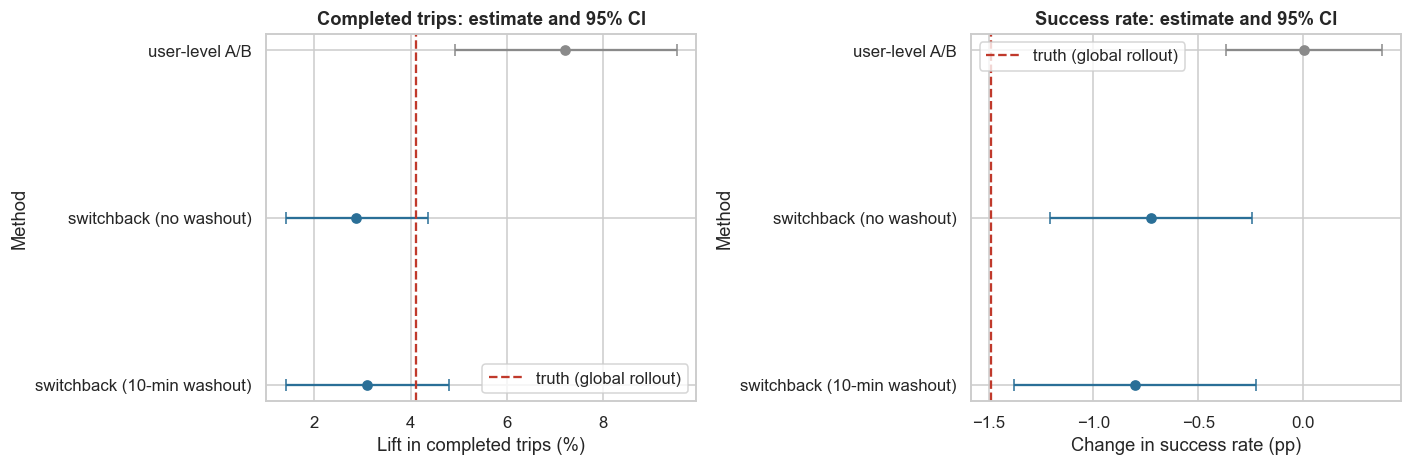

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4)); yy = np.arange(3)[::-1]; cols = ["#8a8a8a", "#2a6f97", "#2a6f97"]
for i, (nm, r) in enumerate(tbl.iloc[:3].iterrows()):
    axes[0].errorbar(r.iloc[0] * 100, yy[i], xerr=[[ (r.iloc[0] - r.iloc[1]) * 100], [(r.iloc[2] - r.iloc[0]) * 100]], fmt="o", color=cols[i], capsize=4)
    axes[1].errorbar(r.iloc[3], yy[i], xerr=[[r.iloc[3] - r.iloc[4]], [r.iloc[5] - r.iloc[3]]], fmt="o", color=cols[i], capsize=4)
axes[0].axvline(TR["_rel_lift_completed"] * 100, color="#c0392b", ls="--", label="truth (global rollout)"); axes[1].axvline(TR["_success_pp"], color="#c0392b", ls="--", label="truth (global rollout)")
for ax, xl, tt in ((axes[0], "Lift in completed trips (%)", "Completed trips: estimate and 95% CI"), (axes[1], "Change in success rate (pp)", "Success rate: estimate and 95% CI")):
    ax.set_yticks(yy); ax.set_yticklabels(["user-level A/B", "switchback (no washout)", "switchback (10-min washout)"]); ax.set_xlabel(xl); ax.set_ylabel("Method"); ax.set_title(tt); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** a user-level A/B shows **+7.2% completed trips (CI +4.9% to +9.5%)**, against a true global-rollout lift of **+4.1%**; its interval does not contain the truth. It also shows **no change in success rate (+0.05 points, CI -0.37 to +0.38)** while the truth is **-1.49 points**, so it misses the harm to the shared pool. The pooled treated-minus-control comparison across minutes gives +1.9% and ignores time effects. Switchbacks give **+2.9% (no washout) and +3.1% (10-minute washout)**, with intervals (1.4% to 4.4% and 1.4% to 4.8%) that include 4.1%. Both switchbacks **understate** the lift and show the success-rate loss only partly (-0.73 and -0.80 points). This is a single run, so section 7.7 repeats it.

### 7.7 Which switchback design recovers the truth? A replication study

**(a) Why?** One experiment cannot show bias; we need many. We repeat the whole 28-day marketplace world **120 times** (new demand and supply paths each time), run each design, and compare the estimate with that world's own true global effect. For each design we report **bias** (mean of estimate − truth, with Monte Carlo SE), **RMSE**, **95% CI coverage** of the truth, **power** (share of CIs excluding zero) and mean CI width.
- **Designs:** alternating 60-minute slots (aliases with the 120-minute supply cycle); alternating 53; purely random 53; **paired-random** 53 (each pair of consecutive slots has one treated and one control, random order); paired-random with 10- and 20-minute washout; paired-random 29 and 112 minutes (10-minute washout); and the **user-level A/B** for reference.
- **Durations:** paired-random 53 with 10-minute washout using the first 7, 14 and 28 days.
- **A/A:** the same designs with a zero effect, 120 repeats, to measure false-positive rates (including the alternating design).
- **Hypotheses:** H0: bias = 0 and coverage = 95%.

#### Code

In [15]:
DESIGNS = {"alternating, 60 min": (60, "alternate", 0), "alternating, 53 min": (53, "alternate", 0), "random, 53 min": (53, "random", 0), "paired-random, 53 min": (53, "block", 0),
           "paired-random, 53 min, washout 10": (53, "block", 10), "paired-random, 53 min, washout 20": (53, "block", 20), "paired-random, 29 min, washout 10": (29, "block", 10), "paired-random, 112 min, washout 10": (112, "block", 10)}
REPS = 120; rec = []; dur = []; t0 = time.time(); T = gen.DAYS_M * 1440
for r in range(REPS):
    paths = gen.market_paths(RNG); tr = gen.truth_global(paths)
    for nm, (L, mode, w) in DESIGNS.items():
        a, iv = gen.interval_assignment(RNG, T, L, mode); s = gen.simulate_market(RNG, paths, a)
        e = sb_est(s.minute.values, s.day.values, s.hour.values, iv, s.treat.values, s.requests.values.astype(float), s.completed.values.astype(float), length=L, washout=w); rec.append((nm, tr["_rel_lift_completed"], tr["_success_pp"], e))
        if nm == "paired-random, 53 min, washout 10":
            for dd_ in (7, 14, 28): dur.append((dd_, tr["_rel_lift_completed"], sb_est(s.minute.values, s.day.values, s.hour.values, iv, s.treat.values, s.requests.values.astype(float), s.completed.values.astype(float), length=L, washout=w, days=dd_)))
    ua, _ = gen.user_level_market_ab(RNG, paths); rec.append(("user-level A/B", tr["_rel_lift_completed"], tr["_success_pp"], ab_est(ua)))
def summarise(recs, key="lift"):
    rows = []
    for nm in dict.fromkeys(r[0] for r in recs):
        rr = [r for r in recs if r[0] == nm]; tl = np.array([r[1] for r in rr]); est = np.array([r[3]["lift"] for r in rr]); lo = np.array([r[3]["lift_lo"] for r in rr]); hi = np.array([r[3]["lift_hi"] for r in rr]); err = est - tl
        spp = np.array([r[3]["sr_pp"] for r in rr]) - np.array([r[2] for r in rr])
        rows.append((nm, tl.mean() * 100, est.mean() * 100, err.mean() * 100, 1.96 * err.std(ddof=1) / np.sqrt(len(err)) * 100, np.sqrt((err ** 2).mean()) * 100, ((lo <= tl) & (tl <= hi)).mean(), ((lo > 0) | (hi < 0)).mean(), (hi - lo).mean() * 100, spp.mean()))
    return pd.DataFrame(rows, columns=["design", "mean truth (%)", "mean estimate (%)", "bias (pp of lift)", "± 95% MC error", "RMSE (pp)", "coverage of truth", "power (CI excludes 0)", "mean CI width (pp)", "success-rate bias (pp)"]).set_index("design")
dsg = summarise(rec); print(f"{REPS} replications × {len(DESIGNS) + 1} designs in {time.time() - t0:.0f}s"); print(dsg.round(3).to_string())
durs = summarise([(f"{d} days", t, 0.0, e) for d, t, e in dur]); print("\nDuration (paired-random 53, washout 10):"); print(durs[["bias (pp of lift)", "RMSE (pp)", "coverage of truth", "power (CI excludes 0)", "mean CI width (pp)"]].round(3).to_string())
# A/A
aa_rows = []
for nm in ("alternating, 60 min", "paired-random, 53 min, washout 10"):
    L, mode, w = DESIGNS[nm]; rej = []; ests = []
    for r in range(REPS):
        paths = gen.market_paths(RNG); a, iv = gen.interval_assignment(RNG, T, L, mode); s = gen.simulate_market(RNG, paths, a, tau=0.0)
        e = sb_est(s.minute.values, s.day.values, s.hour.values, iv, s.treat.values, s.requests.values.astype(float), s.completed.values.astype(float), length=L, washout=w); rej.append(e["lift_p"] < 0.05); ests.append(e["lift"])
    aa_rows.append((nm, np.mean(ests) * 100, np.std(ests, ddof=1) * 100, np.mean(rej)))
aa_tbl = pd.DataFrame(aa_rows, columns=["A/A design (true effect = 0)", "mean estimate (%)", "SD of estimate (%)", "false-positive rate (α = 0.05)"]).set_index("A/A design (true effect = 0)")
print("\nA/A tests (zero effect, switchback designs):"); aa_tbl.round(4)

120 replications × 9 designs in 201s
                                    mean truth (%)  mean estimate (%)  bias (pp of lift)  ± 95% MC error  RMSE (pp)  coverage of truth  power (CI excludes 0)  mean CI width (pp)  success-rate bias (pp)
design                                                                                                                                                                                                   
alternating, 60 min                         4.0900             0.7540            -3.3370          0.0280     3.3410             0.0000                 0.9670              0.7820                 -3.1110
alternating, 53 min                         4.0900             2.1890            -1.9010          0.0240     1.9060             0.0000                 1.0000              2.6080                  0.7440
random, 53 min                              4.0900             3.2550            -0.8350          0.1530     1.1940             0.8080                 0.98


A/A tests (zero effect, switchback designs):


,mean estimate (%),SD of estimate (%),false-positive rate (α = 0.05)
A/A design (true effect = 0),,,
"alternating, 60 min",-1.5911,0.1641,1.0000
"paired-random, 53 min, washout 10",0.0738,0.6536,0.0417


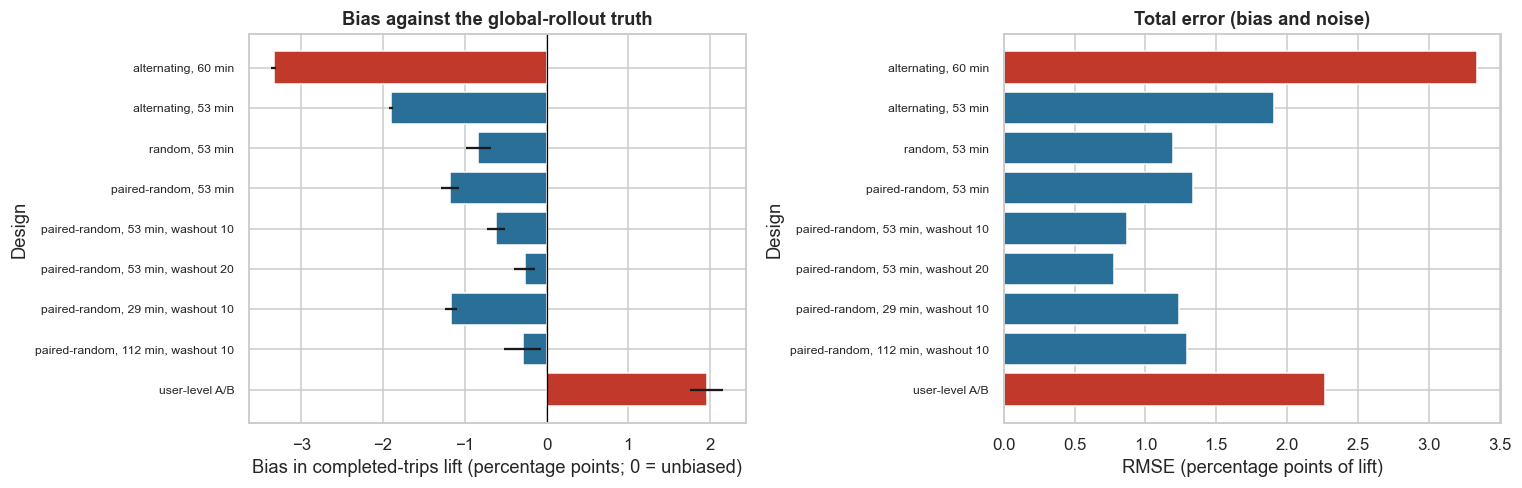

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6)); d_ = dsg.copy(); xs = np.arange(len(d_)); cl = ["#c0392b" if i in (0, len(d_) - 1) else "#2a6f97" for i in xs]
axes[0].barh(xs, d_["bias (pp of lift)"], xerr=d_["± 95% MC error"], color=cl); axes[0].axvline(0, color="black", lw=0.8); axes[0].set_yticks(xs); axes[0].set_yticklabels(d_.index, fontsize=8); axes[0].invert_yaxis(); axes[0].set_xlabel("Bias in completed-trips lift (percentage points; 0 = unbiased)"); axes[0].set_ylabel("Design"); axes[0].set_title("Bias against the global-rollout truth")
axes[1].barh(xs, d_["RMSE (pp)"], color=cl); axes[1].set_yticks(xs); axes[1].set_yticklabels(d_.index, fontsize=8); axes[1].invert_yaxis(); axes[1].set_xlabel("RMSE (percentage points of lift)"); axes[1].set_ylabel("Design"); axes[1].set_title("Total error (bias and noise)")
plt.tight_layout(); plt.show()

**Takeaway:** across 120 simulated worlds, **alternating 60-minute slots are the worst design**: bias **-3.3 points**, coverage of the truth **0%**, and an A/A false-positive rate of **100%** (mean A/A estimate -1.6%), because the slots line up with the 120-minute supply cycle. Alternating 53-minute slots still have bias -1.9 and 0% coverage; random 53-minute slots have bias -0.8 and 81% coverage. **Paired-random 53-minute slots with a 10-minute washout** have bias -0.6, RMSE 0.87, **92% coverage** and an A/A false-positive rate of 4.2%; a 20-minute washout does slightly better (bias -0.27, 93% coverage). Interval length matters: **29 minutes has only 13% coverage** and 112 minutes has 96% coverage but wide intervals (5.1 points) and 84% power. The user-level A/B is biased by **+2.0 points** with 57% coverage. Longer tests narrow the intervals (CI width 6.8 to 2.8 points from 7 to 28 days; power 51% to 100%) but **do not remove the bias (about -0.6 points)**. Washout reduces bias but does not eliminate it here, so switchback estimates should be read as a lower bound.

## 8. ML Section — covariate prediction (CUPAC), and what is beyond it

The case documents no model (the Cabify post is a design and statistics piece). The one place machine learning helps an experiment is **variance reduction**: replace the single pre-period covariate by a *predicted outcome* from a model trained on pre-period features (**CUPAC**). We use gradient boosting with fixed defaults, **5-fold cross-fitting** (each user's prediction comes from a model that did not see that user) and **no arm label** among the features, so the adjustment cannot leak the treatment.

#### Code

In [17]:
feats = ["pre_orders_28d", "pre_sessions_28d", "pre_spend_28d", "new_user", "app", "tier2", "tier3", "pre_spend_28d_missing"]; Xf = D[feats].values; res_ml = []
for c in ("converted", "rev_w"):
    y = D[c].values.astype(float); oof = np.zeros(len(D))
    for trn, tst in KFold(5, shuffle=True, random_state=SEED).split(Xf):
        mdl = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, max_depth=3, random_state=SEED).fit(Xf[trn], y[trn]); oof[tst] = mdl.predict(Xf[tst])
    an0 = smf.ols(f"{c} ~ arm", data=D).fit(cov_type="HC1"); D["_pred"] = oof; an1 = smf.ols(f"{c} ~ arm + _pred", data=D).fit(cov_type="HC1")
    an2 = smf.ols(f"{c} ~ arm + pre_orders_28d + pre_sessions_28d + pre_spend_28d + new_user + C(platform) + C(city_tier)", data=D).fit(cov_type="HC1")
    res_ml.append((c, np.corrcoef(oof, y)[0, 1] ** 2, an0.bse["arm"], an2.bse["arm"], an1.bse["arm"], 1 - (an2.bse["arm"] / an0.bse["arm"]) ** 2, 1 - (an1.bse["arm"] / an0.bse["arm"]) ** 2, an0.params["arm"], an2.params["arm"], an1.params["arm"]))
ml = pd.DataFrame(res_ml, columns=["metric", "R² of out-of-fold prediction", "SE raw", "SE ANCOVA (linear)", "SE CUPAC (GBM)", "variance reduction ANCOVA", "variance reduction CUPAC", "effect raw", "effect ANCOVA", "effect CUPAC"]).set_index("metric"); ml.round(5)

,R² of out-of-fold prediction,SE raw,SE ANCOVA (linear),SE CUPAC (GBM),variance reduction ANCOVA,variance reduction CUPAC,effect raw,effect ANCOVA,effect CUPAC
metric,,,,,,,,,
converted,0.0809,0.0016,0.0015,0.0015,0.0764,0.0808,0.0063,0.0067,0.0067
rev_w,0.0487,2.6364,2.5711,2.5707,0.0489,0.0493,4.3590,4.8998,5.1012


**Observation:** a gradient-boosted prediction of the outcome from pre-period features explains little (out-of-fold **R² = 0.081 for conversion, 0.049 for revenue**). **CUPAC reduces variance by 8.1% for conversion and 4.9% for revenue**, against 7.6% and 4.9% for the linear ANCOVA, so the machine-learning model adds **almost nothing** over regression on this data. Effects barely move (conversion +0.0063 raw, +0.0067 ANCOVA and CUPAC; revenue +₹4.36, +₹4.90 and +₹5.10). The honest conclusion is that the pre-period covariates are the limit; a stronger model cannot create information the features do not hold. Richer behavioural history would be the first thing to test.

- **Beyond this notebook:** modern platforms add **sequential testing** (always-valid p-values), **heterogeneous-effect models** (uplift, Case 22) to target the change, **cluster-robust or synthetic-control** designs for geo tests, and **budget-split experiments** for two-sided marketplaces. They do not remove the need for the checks in 7.1.
- **No tuning** (per the brief): the boosting depth, learning rate and iterations are fixed defaults.

## 9. Business Translation — ₹ impact

Assumptions (D-19-08): **(a) Homepage redesign:** 2 crore (20 million) active users; each is exposed to about 26 two-week windows a year; contribution margin 8% of GMV. The 14-day revenue lift per user is from the covariate-adjusted ANCOVA estimate. Scenarios: worst = lower CI bound with only 50% of the effect persisting (novelty fades); base = point estimate with 80% persisting; best = upper CI bound, full persistence. **(b) Marketplace message:** 3 crore (30 million) completed orders a month, ₹30 contribution per completed order; lifts from 7.6 (user-level A/B vs switchback with 10-minute washout) with CIs as the scenario bounds.

#### Code

In [18]:
USERS, WINDOWS, MARGIN = 2e7, 26, 0.08; an_r = smf.ols("rev_w ~ arm + pre_orders_28d + pre_sessions_28d + pre_spend_28d + new_user + C(platform) + C(city_tier)", data=D).fit(cov_type="HC1")
b, lo, hi = an_r.params["arm"], an_r.conf_int().loc["arm", 0], an_r.conf_int().loc["arm", 1]
sc_ = {"worst (CI low, 50% persists)": (lo, 0.5), "base (estimate, 80% persists)": (b, 0.8), "best (CI high, 100% persists)": (hi, 1.0)}
home = pd.DataFrame({k: {"Δ revenue per user, 14 days (₹)": v[0], "GMV per year (₹ crore)": v[0] * v[1] * USERS * WINDOWS / 1e7, "contribution per year (₹ crore)": v[0] * v[1] * USERS * WINDOWS * MARGIN / 1e7} for k, v in sc_.items()}).T
ORD, UNIT = 3e7, 30.0; rows = []
for nm, e in (("user-level A/B (naive)", (obs_ab["lift"], obs_ab["lift_lo"], obs_ab["lift_hi"])), ("switchback, 10-min washout", (obs_sb[10]["lift"], obs_sb[10]["lift_lo"], obs_sb[10]["lift_hi"]))):
    rows.append((nm, *[v * ORD * UNIT * 12 / 1e7 for v in (e[1], e[0], e[2])], e[0]))
rows.append(("truth (hidden global rollout)", np.nan, TR["_rel_lift_completed"] * ORD * UNIT * 12 / 1e7, np.nan, TR["_rel_lift_completed"]))
mkt = pd.DataFrame(rows, columns=["method", "₹ crore / year (worst: CI low)", "₹ crore / year (base)", "₹ crore / year (best: CI high)", "lift used"]).set_index("method")
over = (obs_ab["lift"] - TR["_rel_lift_completed"]) * ORD * UNIT * 12 / 1e7
print(f"Homepage (ANCOVA effect on 14-day revenue per user: ₹{b:.2f}, 95% CI {lo:.2f} to {hi:.2f})"); print(home.round(2).to_string()); print(f"\nMarketplace: the naive A/B point estimate overstates the true yearly value by ₹{over:.1f} crore"); mkt.round(3)

Homepage (ANCOVA effect on 14-day revenue per user: ₹4.90, 95% CI -0.14 to 9.94)
                               Δ revenue per user, 14 days (₹)  GMV per year (₹ crore)  contribution per year (₹ crore)
worst (CI low, 50% persists)                           -0.1400                 -3.6200                          -0.2900
base (estimate, 80% persists)                           4.9000                203.8300                          16.3100
best (CI high, 100% persists)                           9.9400                516.8300                          41.3500

Marketplace: the naive A/B point estimate overstates the true yearly value by ₹33.3 crore


,₹ crore / year (worst: CI low),₹ crore / year (base),₹ crore / year (best: CI high),lift used
method,,,,
user-level A/B (naive),53.1910,77.7550,102.8510,0.0720
"switchback, 10-min washout",15.2680,33.3760,51.7840,0.0310
truth (hidden global rollout),NaN,44.4780,NaN,0.0410


**Takeaway (business reading):** **Homepage:** the base case is **+₹4.90 revenue per user over 14 days**, which at 2 crore users and 26 windows a year is about **₹204 crore of GMV and ₹16.3 crore of contribution a year**. The range is wide because revenue is inconclusive: the worst case is **-₹0.3 crore** and the best case **+₹41.3 crore** (₹517 crore GMV). **Marketplace message:** the naive user-level A/B implies **₹77.8 crore a year (₹53 to ₹103 crore)**, the 10-minute-washout switchback **₹33.4 crore (₹15 to ₹52 crore)** and the hidden truth is **₹44.5 crore**. Trusting the naive A/B would overstate the value by **₹33.3 crore a year**; the switchback understates it by about ₹11 crore, a smaller and more conservative error. The assumptions are in D-19-08 and only the comparison between methods is robust.

## 10. Recommendation and Decision

**Recommendation**

1. **Homepage: ramp, do not declare a revenue win.** Conversion is up 8.6% relative (Holm p = 0.0004) and guardrails pass, but revenue per user is inconclusive (CI -₹0.8 to +₹9.5). Ramp 10% to 50% to 100% over two weeks, keep a **5% holdback for 4 to 6 weeks**, and judge revenue on the holdback.
2. **Fix the web logging fault** behind the days-5-and-6 sample-ratio mismatch before the next test; keep the automatic SRM check (alert at p < 0.001) as a launch gate.
3. **Marketplace and supply-sharing changes: use a paired-random switchback**, 53-minute slots, 10-minute washout, at least 14 days (28 preferred). Never use alternating slots that match a 60 or 120 minute cycle, and do not use a user-level A/B for success rate.
4. **If the team peeks, use O'Brien-Fleming looks**, not repeated 5% tests.
5. **Report revenue winsorised** (99.9th percentile) next to raw, and use ANCOVA by default (modest gain).

**Decision rule:** ship if the primary metric's Holm-adjusted p < 0.05 with a positive CI, no guardrail breaches its margin (bounce +0.5 points, page load +3%, support contacts +0.3 points), SRM p > 0.001, and the holdback shows revenue per user not below control.

**KPIs to monitor:** SRM p-value per test, conversion lift with CI, winsorised revenue per user, support-contact rate (closest to its margin), page load, marketplace success rate by hour, A/A false-positive rate (target 5% ± 1 point).

## 11. Risks, Limitations and Next Steps

- **Simulated worlds:** effect sizes, the congestion curve (success = 0.97 × (1 − exp(−1.8 × supply/demand))) and the 12-minute carryover are assumptions. The interference bias scales with how strongly demand and supply interact; re-estimate it for each marketplace with an A/A switchback.
- **Single-market switchback:** one city, one metric. Real tests span regions and have a few weeks at most; with fewer intervals, power falls (7.7 duration table).
- **The user-level A/B in the market world is simplified:** user outcomes use the period-average success rate rather than time-matched success, so its CI ignores correlation through time.
- **CUPED helps, but modestly here:** the covariate explains only a small share of revenue variance because most users do not buy in 14 days. New users have no pre-period at all.
- **Novelty and long-run effects** are not modelled; run long-term holdouts on big launches.
- **Next steps:** add sequential monitoring to the platform with automated SRM alarms; build a switchback template (paired-random, 53-minute slots, 10-minute washout, day-clustered errors) with an A/A pre-check; connect to uplift targeting (Case 22) and budget-split designs.

## 12. Appendix

| Quantity | Formula |
|---|---|
| SRM chi-square | Σ (observed − expected)² / expected, expected = N/2 per arm |
| Standardised mean difference | (m₁ − m₀) / √((s₁² + s₀²)/2) |
| Welch z | (ȳ₁ − ȳ₀) / √(s₁²/n₁ + s₀²/n₀) |
| Holm | sort p; reject p₍ᵢ₎ ≤ α/(m − i + 1) stepwise |
| Benjamini-Hochberg | largest i with p₍ᵢ₎ ≤ α·i/m |
| CUPED | y_adj = y − θ(x − x̄), θ = cov(y, x)/var(x); variance × (1 − ρ²) |
| MDE (two proportions) | (z₁₋α/₂ + z₁₋β) √(p(1 − p)(1/n_T + 1/n_C)) |
| Group-sequential boundary | Pocock: constant c; O'Brien-Fleming: c·√(K/k) at look k |
| Success probability (simulation) | 0.97 × (1 − exp(−1.8 · supply/demand)) |
| Switchback estimator | log(trips per minute)ᵢ = α + β·treatᵢ + block FE + weekend + ε; lift = exp(β) − 1; SE clustered by day |

| Term | Meaning |
|---|---|
| A/B test | Randomise users into versions and compare |
| SRM | Sample-ratio mismatch: arm sizes differ from the design |
| CUPED | Variance reduction using pre-experiment data |
| Guardrail metric | A metric that must not get worse |
| Interference / cannibalization | One user's treatment affects other users' outcomes through shared supply |
| Switchback | Randomise time slots instead of users |
| Washout | Dropping the start of each slot while the effect builds up |
| Carryover | The effect of the previous slot leaking into the next |
| Peeking | Looking at results repeatedly and stopping when significant |
| Non-inferiority | Showing a harm is smaller than a pre-set margin |